# Convolving the $F_3^{\gamma Z}$ FK table with the PDF

Convolve the `HERA_F3_aZ` FK table with a PDF to predict $xF_3^{\gamma Z}$ for the HERA dataset, and compare to data.

In [15]:
import pineappl
import numpy as np
import lhapdf
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.ticker as mticker
from eko import basis_rotation as br

## Load HERA data

In [16]:
# table 7 in https://arxiv.org/pdf/1506.06042
with open("HERA_xF3.json") as f:
    hera_data = json.load(f)

data = {"x": [], "Q2": [], "exp_cv": [], "exp_error": []}
for dat in hera_data["values"]:
    Q2 = dat["x"][0]["value"]
    x = dat["x"][1]["value"]
    xF3 = dat["y"][0]["value"]
    error = 0
    for error_type in dat["y"][0]["errors"]:
        error += float(error_type["symerror"]) ** 2
    error = error ** 0.5
    data["exp_error"].append(error)
    data["Q2"].append(float(Q2))
    data["x"].append(float(x))
    data["exp_cv"].append(float(xF3))
data = pd.DataFrame(data)

data = {"x": [], "Q2": [], "exp_cv": [], "exp_error": []}
for dat in hera_data["values"]:
    Q2 = dat["x"][0]["value"]
    x = dat["x"][1]["value"]
    xF3 = dat["y"][0]["value"]
    error = 0
    for error_type in dat["y"][0]["errors"]:
        error += float(error_type["symerror"]) ** 2
    error = error ** 0.5
    data["exp_error"].append(error)
    data["Q2"].append(float(Q2))
    data["x"].append(float(x))
    data["exp_cv"].append(float(xF3))
data = pd.DataFrame(data)

## Load FK table and kinematic prefactor

In [17]:
fk = pineappl.fk_table.FkTable.read("fk_tables/40000000/HERA_F3_aZ.pineappl.lz4")
pdfset = "NNPDF40_nnlo_as_01180"
bin_specs = np.array(fk.bin_limits())
q2 = np.unique(bin_specs[:, 0, 0])  # Q2 in the 1st dimension
x = np.unique(bin_specs[:, 1, 0])  # x in 2nd dimension

q2_max = max(q2)

mZ = 91.1876
sth2 = 0.23126
cth2 = 1 - sth2
kZ = data["Q2"]/((data["Q2"] + mZ ** 2) * 4 * cth2 * sth2)  # see Eq.2 in https://arxiv.org/pdf/1506.06042
prefactor = 2 / kZ
prefactor_arr = np.asarray(prefactor)


## Evolution-basis setup

Build the evolution-basis channel table, x-grid, and a helper to evaluate any evolution-basis combination from a flavor-basis PDF (NNPDF4.0) at $Q_0$.

In [18]:
channels = [c[0] for c in fk.channels()]  # evolution-basis PIDs, in fk.table()'s channel order
table = np.array(fk.table())              # shape (n_bins, n_channels, n_x)
xgrid = np.array(fk.x_grid())             # shape (n_x,): the FK table's own interpolation nodes

M = np.array(br.rotate_flavor_to_evolution, dtype=float)  # evol_vector = M @ flavor_vector

Q0 = 1.65
Q02 = Q0 ** 2
assert np.isclose(fk.fac0(), Q02)

# load the baseline PDF (NNPDF4.0) that we will use for every channel we are not fitting
baseline_pdf = lhapdf.mkPDF(pdfset, 0)

def evol_val(pid, x, pdf=baseline_pdf, Q02=Q02):
    """Computes the contribution of a single evolution-basis PDF at Q0, for a given x."""
    flavor_vec = np.array([pdf.xfxQ2(p, x, Q02) for p in br.flavor_basis_pids])
    return (M @ flavor_vec)[br.evol_basis_pids.index(pid)]

LHAPDF 6.5.5 loading /Users/jaco/miniconda3/envs/nnpdf_dev/share/LHAPDF/NNPDF40_nnlo_as_01180/NNPDF40_nnlo_as_01180_0000.dat
NNPDF40_nnlo_as_01180 PDF set, member #0, version 1; LHAPDF ID = 331100


## Which evolution-basis channel dominates?

Break the prediction down by evolution-basis channel (each evaluated with NNPDF4.0 at $Q_0$) to decide which single channel is worth fitting while holding the rest fixed.

In [19]:
evol_names = dict(zip(br.evol_basis_pids, br.evol_basis))

channel_contribs = {}
for ci, pid in enumerate(channels):
    vals = np.array([evol_val(pid, x) for x in xgrid])  # NNPDF4.0 at Q0 for this channel
    contrib = (table[:, ci, :] / xgrid[None, :]) @ vals * prefactor_arr
    channel_contribs[pid] = contrib

summary = pd.DataFrame({
    "channel": [evol_names[pid] for pid in channel_contribs],
    "pid": list(channel_contribs.keys()),
    "rms": [np.sqrt(np.mean(c ** 2)) for c in channel_contribs.values()],
}).sort_values("rms", ascending=False).reset_index(drop=True)
summary["rms_%_of_total"] = 100 * summary["rms"] / summary["rms"].sum()

print(summary.to_string(index=False))

channel  pid          rms  rms_%_of_total
      V  200 2.733034e-01    7.448533e+01
     V3  203 3.475074e-02    9.470868e+00
    V15  215 3.026942e-02    8.249544e+00
     V8  208 2.859890e-02    7.794262e+00
      S  100 8.653246e-17    2.358331e-14
    T15  115 3.411234e-17    9.296881e-15
      g   21 2.767523e-17    7.542530e-15
     T8  108 1.667692e-17    4.545082e-15
     T3  103 5.899247e-18    1.607764e-15


## Fixing all flavours but V

$V$ (total valence) dominates $xF_3^{\gamma Z}$ by roughly an order of magnitude over the next-largest channels — see the breakdown above. Fit $V$ while holding every other evolution-basis channel, including $V_3$, fixed to NNPDF4.0.

In [20]:
target_pid = 200  # V: total valence, found to dominate xF3^{gammaZ} in the breakdown above
target_ci = channels.index(target_pid)

# select the target channel and divide by xgrid to get the matrix W that multiplies V(x, Q0)
W = table[:, target_ci, :] / xgrid[None, :]  # shape (n_bins, n_x)

# build the offset from all other channels
offset = np.zeros(table.shape[0])
for ci, pid in enumerate(channels):
    if ci == target_ci:
        continue
    vals = np.array([evol_val(pid, x) for x in xgrid])  # NNPDF4.0 at Q0 for this channel
    offset += (table[:, ci, :] / xgrid[None, :]) @ vals

# absorb the xF3^{gammaZ} prefactor so that `W @ V + offset` is the final prediction directly
W *= prefactor_arr[:, None]
offset *= prefactor_arr


In [21]:
# sanity check: plug NNPDF4.0's own V back in -> W @ V + offset must reproduce fk.convolve * prefactor exactly
v_V_nnpdf40 = np.array([evol_val(target_pid, x) for x in xgrid])
y_theory_roundtrip = W @ v_V_nnpdf40 + offset

pred_ref = fk.convolve(pdg_convs=fk.convolutions, xfxs=[baseline_pdf.xfxQ2]) * prefactor_arr
print("max abs deviation from fk.convolve:", np.max(np.abs(y_theory_roundtrip - pred_ref)))


max abs deviation from fk.convolve: 2.220446049250313e-16


### Conditioning of W

$W$ is the (67, 30) matrix mapping $V(x, Q_0)$ on the FK x-grid to the prediction. Its singular values indicate how well-constrained a fit of $V$ on this grid is.

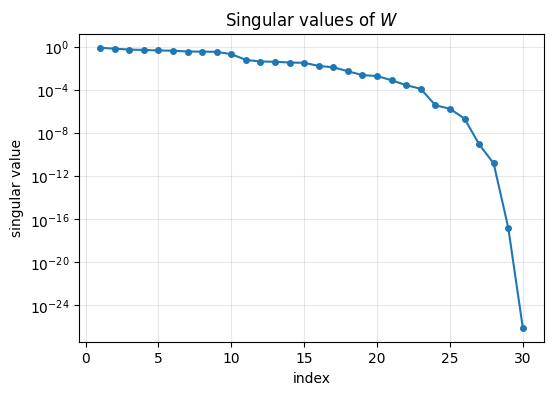

condition number: 9.32e+25


In [22]:
singular_values = np.linalg.svd(W, compute_uv=False)

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(np.arange(1, len(singular_values) + 1), singular_values, "o-", ms=4)
ax.set_xlabel("index")
ax.set_ylabel("singular value")
ax.set_title(r"Singular values of $W$")
ax.grid(True, which="both", alpha=0.3)
plt.show()

print(f"condition number: {singular_values[0] / singular_values[-1]:.3g}")

Compare the $x$-spacing of the data to the $x$-spacing of the FK table's interpolation grid, to see the resolution mismatch directly.

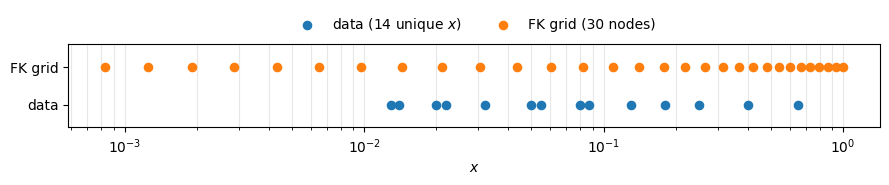

In [23]:
data_x_unique = np.sort(data["x"].unique())

fig, ax = plt.subplots(figsize=(9, 2.5))
ax.scatter(data_x_unique, np.zeros_like(data_x_unique), color="C0", s=35, zorder=3, label=f"data ({len(data_x_unique)} unique $x$)")
ax.scatter(xgrid, np.ones_like(xgrid), color="C1", s=35, zorder=3, label=f"FK grid ({len(xgrid)} nodes)")

ax.set_xscale("log")
ax.set_yticks([0, 1])
ax.set_yticklabels(["data", "FK grid"])
ax.set_ylim(-0.6, 1.6)
ax.set_xlabel("$x$")
ax.grid(True, axis="x", which="both", alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.5), ncols=2, frameon=False)
plt.tight_layout()
plt.show()

### Restricting to grid nodes within the data's x-range

Fix $V$ at the grid nodes outside $[\min(x_\text{data}), \max(x_\text{data})]$ to NNPDF4.0, folding their (already near-zero) contribution into `offset`, and only fit the nodes inside the data's range.

17 / 30 grid nodes lie within the data's x-range [0.013, 0.65]
max abs deviation from full W @ V + offset: 1.6653345369377348e-16
condition number (in-range nodes only): 696


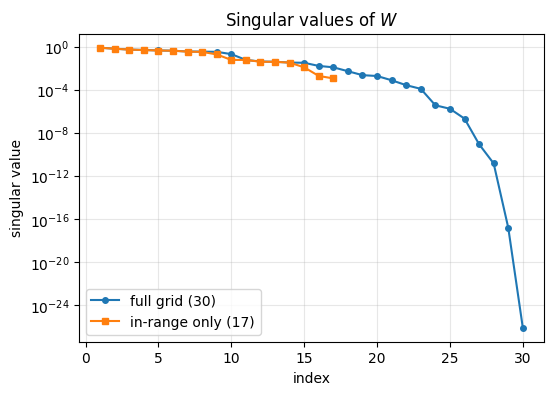

In [24]:
in_range = (xgrid >= data_x_unique.min()) & (xgrid <= data_x_unique.max())
print(f"{in_range.sum()} / {len(xgrid)} grid nodes lie within the data's x-range [{data_x_unique.min():.3g}, {data_x_unique.max():.3g}]")

xgrid_sub = xgrid[in_range]
W_sub = W[:, in_range]
# fix the out-of-range nodes to NNPDF4.0, folding their contribution into the offset
offset_sub = offset + W[:, ~in_range] @ v_V_nnpdf40[~in_range]

# sanity check: this must be an exact re-partition of the same prediction
roundtrip_sub = W_sub @ v_V_nnpdf40[in_range] + offset_sub
print("max abs deviation from full W @ V + offset:", np.max(np.abs(roundtrip_sub - (W @ v_V_nnpdf40 + offset))))

sv_sub = np.linalg.svd(W_sub, compute_uv=False)
print(f"condition number (in-range nodes only): {sv_sub[0] / sv_sub[-1]:.3g}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(np.arange(1, len(singular_values) + 1), singular_values, "o-", ms=4, label=f"full grid ({len(xgrid)})")
ax.semilogy(np.arange(1, len(sv_sub) + 1), sv_sub, "s-", ms=4, label=f"in-range only ({len(xgrid_sub)})")
ax.set_xlabel("index")
ax.set_ylabel("singular value")
ax.set_title(r"Singular values of $W$")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.show()

### Usage

In [25]:
# @Richard, it is possible to define a custom V (vectorised over the in-range grid nodes), i.e. V_func(x) -> x * V(x, Q0), and then compute the predictions as
# v_V_fit = V_func(xgrid_sub)
# predictions_fit = W_sub @ v_V_fit + offset_sub

## Data vs. theory comparison

Predictions built from `W_sub @ V + offset_sub` (fitting only the grid nodes within the data's x-range), using NNPDF4.0's own $V$ for now (replace by a fitted $V$ later).


In [26]:
# V = NNPDF4.0 for now; replace with a fitted V_func(xgrid_sub) later
# prefactor is already absorbed into W_sub, offset_sub
predictions = W_sub @ v_V_nnpdf40[in_range] + offset_sub


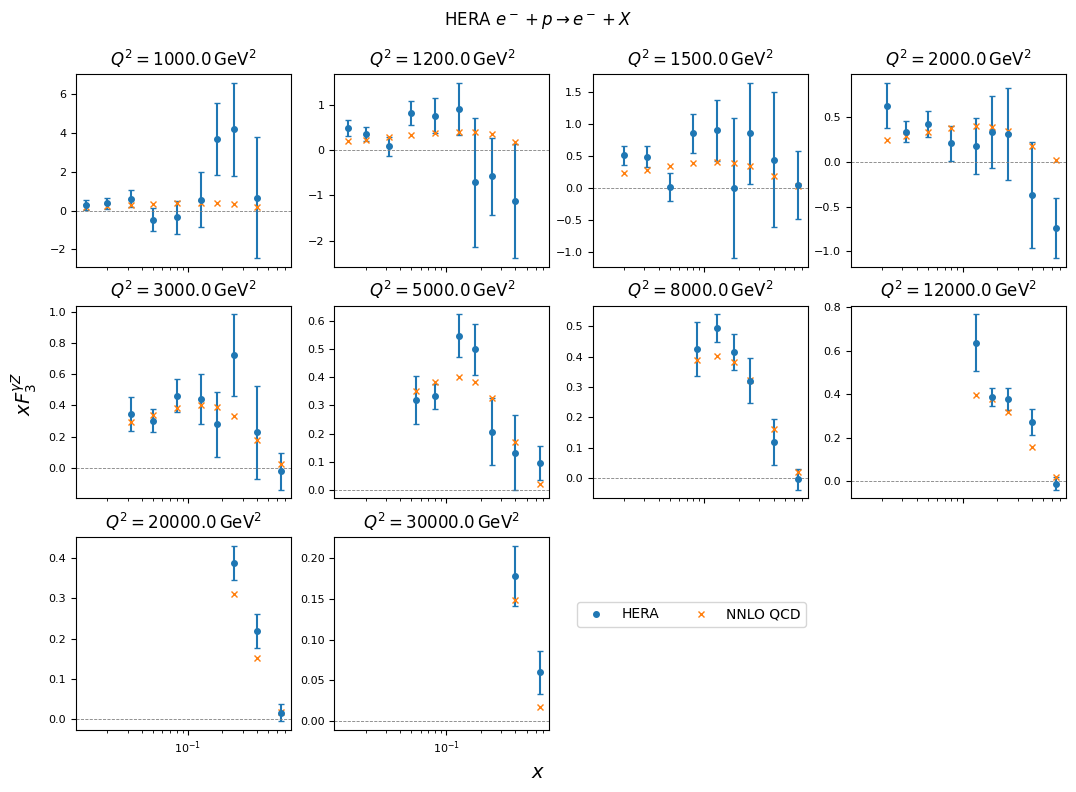

In [27]:
q2_values = np.sort(data["Q2"].unique())
n_used = len(q2_values)

fig, axes = plt.subplots(
    3, 4,
    figsize=(11, 8),
    sharex=True,
    sharey=False
)

fig.suptitle(r"HERA $e^- + p \to e^- + X$")

# Make panels touch
fig.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.08,
    top=0.9,
    wspace=0.2,
    hspace=0.2
)

axes_flat = axes.flatten()

exp_handle = None
th_handle = None

for i, (q2, ax) in enumerate(zip(q2_values, axes_flat)):
    dat = data[data["Q2"] == q2]

    # Plot data
    eb = ax.errorbar(
        dat["x"], dat["exp_cv"],
        yerr=dat["exp_error"],
        fmt="o", capsize=2, ms=4
    )
    if exp_handle is None:
        exp_handle = eb[0]

    (pth,) = ax.plot(dat["x"], predictions[data["Q2"] == q2], "x", ms=5)
    if th_handle is None:
        th_handle = pth

    # Log axis
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(mticker.LogLocator(base=10))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())

    # Zero line
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.6)

    ax.set_title(f"$Q^2 = {q2} \\, \\mathrm{{GeV}}^2$")

    # Tick formatting
    ax.tick_params(axis="both", labelsize=8)

# Remove unused axes
for ax in axes_flat[n_used:]:
    fig.delaxes(ax)


# Global axis labels
fig.text(0.5, 0.02, r"$x$", ha="center", fontsize=14)
fig.text(0.02, 0.5, r"$xF_3^{\gamma Z}$", va="center",
         rotation="vertical", fontsize=14)

# Legend
fig.legend(
    handles=[exp_handle, th_handle],
    labels=["HERA", "NNLO QCD"],
    loc="lower right",
    ncols=2,
    frameon=True,
    bbox_to_anchor=(0.75, 0.2),
)


In [28]:
# compute the chi2
chi2 = np.sum(((predictions - data["exp_cv"]) / data["exp_error"]) ** 2)
print(f"Chi2: {chi2:.2f} / {len(data)} = {chi2/len(data):.2f}")


Chi2: 80.49 / 67 = 1.20
